## WorldTrace Time-Conditioned Mobility in South Brooklyn (Flag 5)

### Dataset Overview

64 constructed vehicle trajectories across four days in one South Brooklyn road corridor. All point geometries are forward subroutes of the cached OSRM road polyline; timestamps are integrated from segment distances and endpoint speeds. Detour score is route distance divided by endpoint great-circle distance. Context and speed profiles are constructed; these are not original GPS observations.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Analyze the provided trajectories within a common area and identify how their movement characteristics vary across time periods.

Role: NYC mobility insight analyst


Category: Time-Conditioned Trajectory Characteristics


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "05_context_conditioned_patterns.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How are the start times of vehicle trajectories distributed between daytime and non-daytime hours on cold days?

#### Analysis action

Use the daytime concentration as an observed temporal pattern for this area, without treating the temperature grouping as a causal explanation.

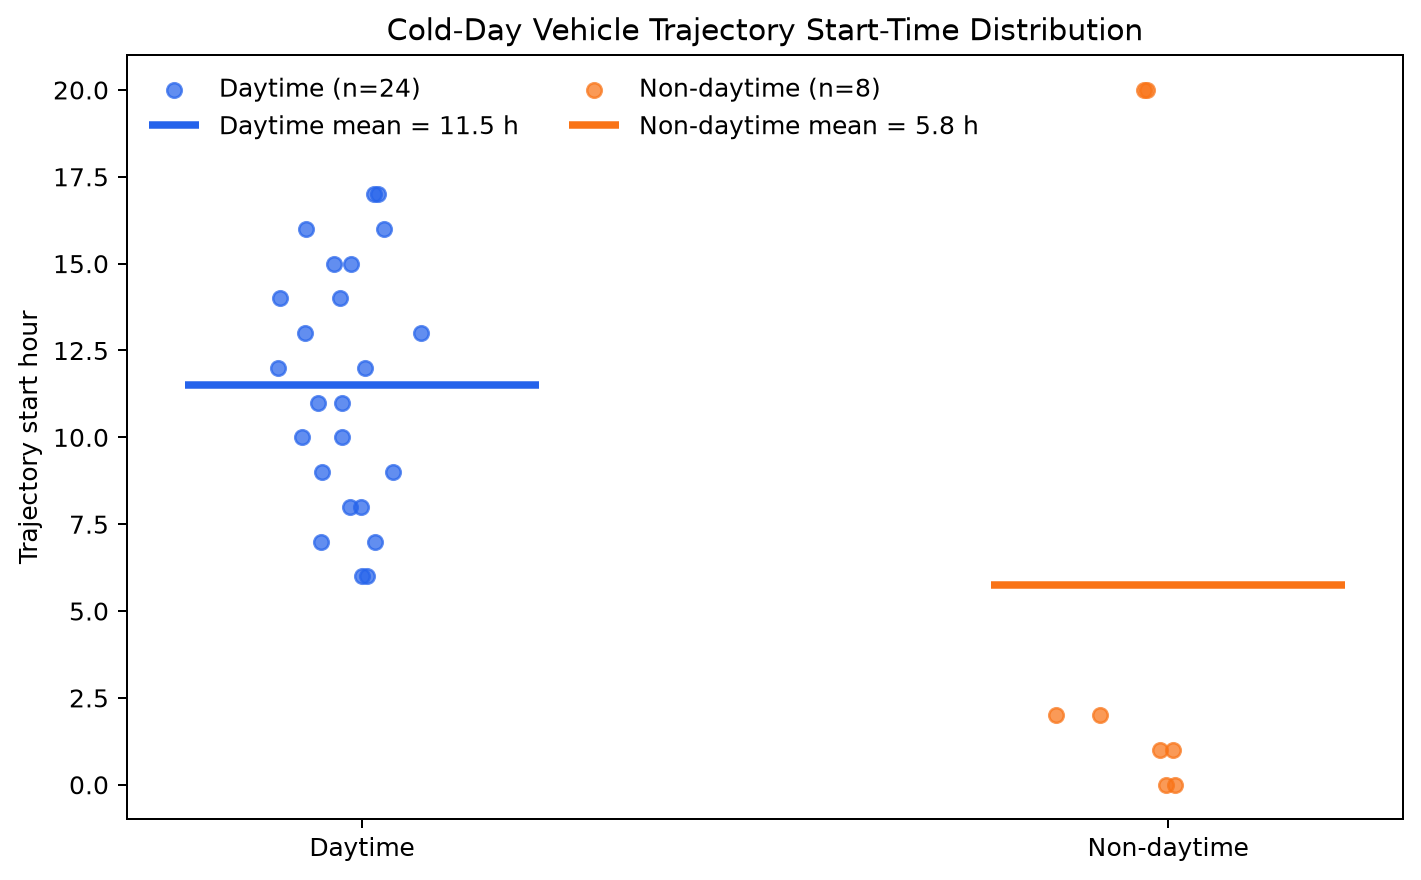

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

cold = df[df["temperature_2m_c"] < 5].copy()
cold["period"] = np.where(cold["hour"].between(6, 18), "Daytime", "Non-daytime")
colors = {"Daytime": "#2563eb", "Non-daytime": "#f97316"}
fig, ax = plt.subplots(figsize=(8, 5))
rng = np.random.default_rng(7)
for x, period in enumerate(["Daytime", "Non-daytime"]):
    values = cold.loc[cold["period"] == period, "hour"].to_numpy()
    jitter = rng.normal(0, 0.055, size=len(values))
    ax.scatter(
        np.full(len(values), x) + jitter,
        values,
        color=colors[period],
        alpha=0.72,
        s=34,
        label=f"{period} (n={len(values)})",
    )
    ax.hlines(
        values.mean(),
        x - 0.22,
        x + 0.22,
        color=colors[period],
        linewidth=3,
        label=f"{period} mean = {values.mean():.1f} h",
    )
ax.set_xticks([0, 1], ["Daytime", "Non-daytime"])
ax.set_ylabel("Trajectory start hour")
ax.set_title("Cold-Day Vehicle Trajectory Start-Time Distribution")
ax.legend(frameon=False, ncol=2)
plt.tight_layout()
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/cold_day_vehicle_start_time_distribution.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "On cold days, more vehicle trajectories pass through the South Brooklyn area during daytime hours than during non-daytime hours.",
  "insight_value": {
    "cold_daytime_count": 24,
    "cold_non_daytime_count": 8,
    "cold_daytime_definition": "06:00-18:00",
    "cold_temperature_threshold_c": 5
  },
  "plot": {
    "plot_type": "trajectory_distribution_with_group_means",
    "title": "Cold-Day Vehicle Trajectory Start-Time Distribution",
    "description": "Each point is one cold-day vehicle trajectory. Daytime and non-daytime trajectories use different colors, and horizontal lines show the mean start hour for each group; the point counts show the daytime concentration without using a bar chart.",
    "file": "visualizations/cold_day_vehicle_start_time_distribution.png"
  },
  "question": "How are the start times of vehicle trajectories distributed between daytime and non-daytime hours on cold days?",
  "actionable_insight": "Use the daytime concentration as an observed temporal pattern for this area, without treating the temperature grouping as a causal explanation.",
  "code": "import matplotlib.pyplot as plt\nimport numpy as np\n\ncold = df[df[\"temperature_2m_c\"] < 5].copy()\ncold[\"period\"] = np.where(cold[\"hour\"].between(6, 18), \"Daytime\", \"Non-daytime\")\ncolors = {\"Daytime\": \"#2563eb\", \"Non-daytime\": \"#f97316\"}\nfig, ax = plt.subplots(figsize=(8, 5))\nrng = np.random.default_rng(7)\nfor x, period in enumerate([\"Daytime\", \"Non-daytime\"]):\n values = cold.loc[cold[\"period\"] == period, \"hour\"].to_numpy()\n jitter = rng.normal(0, 0.055, size=len(values))\n ax.scatter(np.full(len(values), x) + jitter, values, color=colors[period], alpha=0.72, s=34, label=f\"{period} (n={len(values)})\")\n ax.hlines(values.mean(), x - 0.22, x + 0.22, color=colors[period], linewidth=3, label=f\"{period} mean = {values.mean():.1f} h\")\nax.set_xticks([0, 1], [\"Daytime\", \"Non-daytime\"])\nax.set_ylabel(\"Trajectory start hour\")\nax.set_title(\"Cold-Day Vehicle Trajectory Start-Time Distribution\")\nax.legend(frameon=False, ncol=2)\nplt.tight_layout()\nplt.show()",
  "insight_type": "factor_relationship",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "temperature",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 2**: How does route indirectness vary across the time periods, and which period has the highest scores?

#### Analysis action

Treat the afternoon route-indirectness elevation as an observed time-of-day difference in this common area, not as proof of its cause.

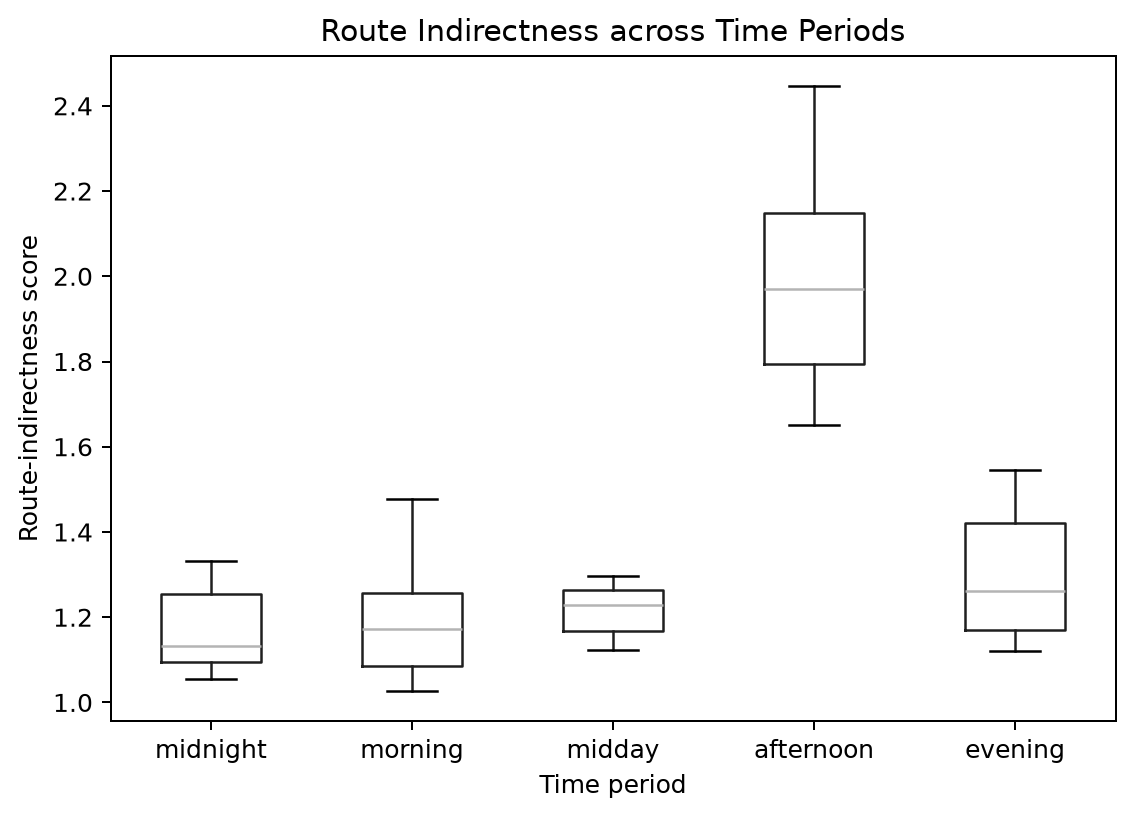

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

bins = [-1, 5, 10, 12, 17, 23]
labels = ["midnight", "morning", "midday", "afternoon", "evening"]
df = df.copy()
df["time_period"] = pd.cut(df["hour"], bins=bins, labels=labels)
df.boxplot(column="detour_score", by="time_period", grid=False)
plt.suptitle("")
plt.title("Route Indirectness across Time Periods")
plt.xlabel("Time period")
plt.ylabel("Route-indirectness score")
plt.tight_layout()
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="notebook_plots/q2_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "Afternoon trajectories usually have higher route-indirectness scores than trajectories in the other time periods.",
  "insight_value": {
    "mean_route_indirectness": {
      "midnight": 1.174,
      "morning": 1.191,
      "midday": 1.216,
      "afternoon": 2.0,
      "evening": 1.307
    },
    "median_route_indirectness": {
      "midnight": 1.131,
      "morning": 1.173,
      "midday": 1.228,
      "afternoon": 1.971,
      "evening": 1.262
    }
  },
  "plot": {
    "plot_type": "boxplot",
    "title": "Route Indirectness across Time Periods",
    "x_axis": {
      "name": "Time period",
      "description": "Midnight, morning, midday, afternoon, or evening based on trajectory start hour."
    },
    "y_axis": {
      "name": "Route-indirectness score",
      "description": "The trajectory-level route-indirectness summary."
    },
    "description": "The distribution view shows whether afternoon trajectories are generally more indirect rather than relying on one average.",
    "file": "notebook_plots/q2_1.png"
  },
  "question": "How does route indirectness vary across the time periods, and which period has the highest scores?",
  "actionable_insight": "Treat the afternoon route-indirectness elevation as an observed time-of-day difference in this common area, not as proof of its cause.",
  "code": "import matplotlib.pyplot as plt\nimport pandas as pd\n\nbins = [-1, 5, 10, 12, 17, 23]\nlabels = [\"midnight\", \"morning\", \"midday\", \"afternoon\", \"evening\"]\ndf = df.copy()\ndf[\"time_period\"] = pd.cut(df[\"hour\"], bins=bins, labels=labels)\ndf.boxplot(column=\"detour_score\", by=\"time_period\", grid=False)\nplt.suptitle(\"\")\nplt.title(\"Route Indirectness across Time Periods\")\nplt.xlabel(\"Time period\")\nplt.ylabel(\"Route-indirectness score\")\nplt.tight_layout()\nplt.show()",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 3**: Which time periods have the highest average trajectory speeds, and how do they compare with the other periods?

#### Analysis action

Use morning and midnight as the high-speed reference periods for this area when comparing time-of-day trajectory behaviour.

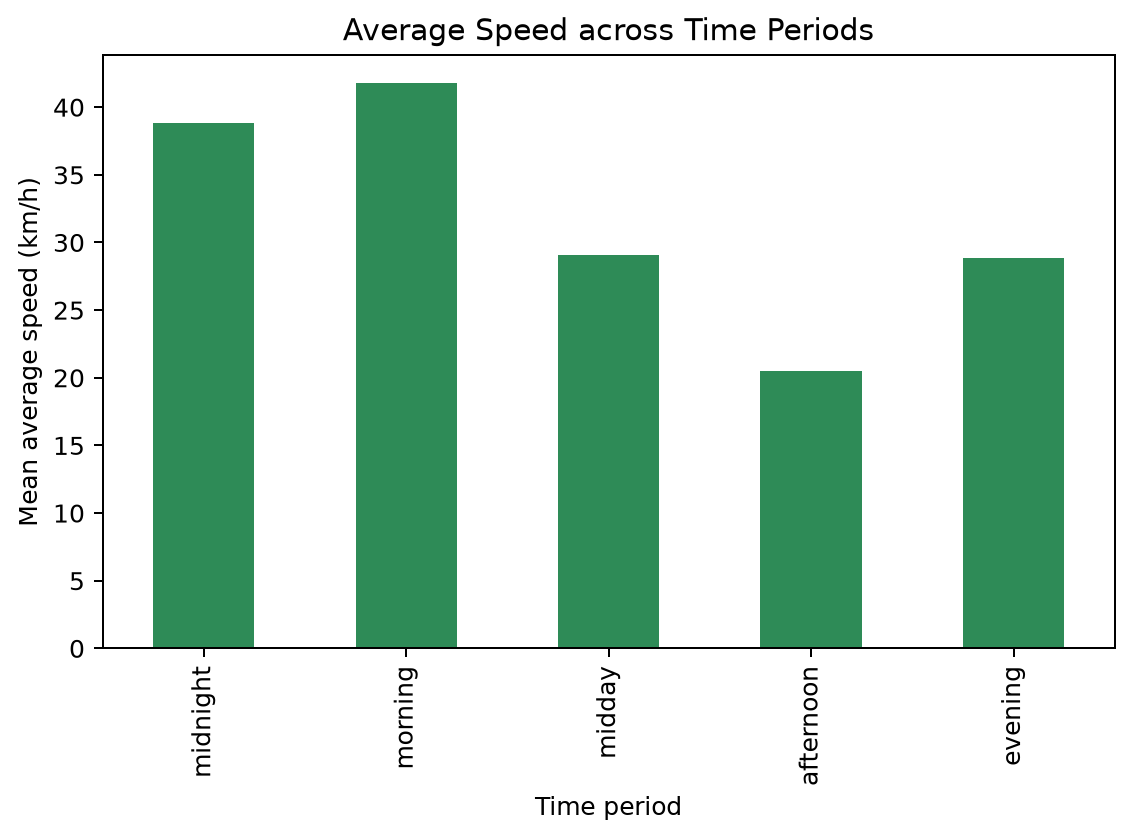

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

bins = [-1, 5, 10, 12, 17, 23]
labels = ["midnight", "morning", "midday", "afternoon", "evening"]
df = df.copy()
df["time_period"] = pd.cut(df["hour"], bins=bins, labels=labels)
means = (
    df.groupby("time_period", observed=False)["avg_speed_kmh"].mean().reindex(labels)
)
means.plot(kind="bar", color="seagreen")
plt.title("Average Speed across Time Periods")
plt.xlabel("Time period")
plt.ylabel("Mean average speed (km/h)")
plt.tight_layout()
plt.close("all")
plt.close("all")
# Display the verified visualization once.
display(Image(filename="notebook_plots/q3_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "descriptive",
  "insight": "Trajectories in the morning and around midnight have much higher average speeds than trajectories in the other time periods.",
  "insight_value": {
    "mean_speed_kmh": {
      "midnight": 38.838,
      "morning": 41.754,
      "midday": 29.086,
      "afternoon": 20.5,
      "evening": 28.837
    },
    "median_speed_kmh": {
      "midnight": 38.505,
      "morning": 42.28,
      "midday": 29.759,
      "afternoon": 20.873,
      "evening": 28.782
    }
  },
  "plot": {
    "plot_type": "bar",
    "title": "Average Speed across Time Periods",
    "x_axis": {
      "name": "Time period",
      "description": "Midnight, morning, midday, afternoon, or evening based on trajectory start hour."
    },
    "y_axis": {
      "name": "Mean average speed (km/h)",
      "description": "The mean trajectory-level average speed within each time period."
    },
    "description": "The period-level speed comparison highlights the higher morning and midnight averages.",
    "file": "notebook_plots/q3_1.png"
  },
  "question": "Which time periods have the highest average trajectory speeds, and how do they compare with the other periods?",
  "actionable_insight": "Use morning and midnight as the high-speed reference periods for this area when comparing time-of-day trajectory behaviour.",
  "code": "import matplotlib.pyplot as plt\nimport pandas as pd\n\nbins = [-1, 5, 10, 12, 17, 23]\nlabels = [\"midnight\", \"morning\", \"midday\", \"afternoon\", \"evening\"]\ndf = df.copy()\ndf[\"time_period\"] = pd.cut(df[\"hour\"], bins=bins, labels=labels)\nmeans = df.groupby(\"time_period\", observed=False)[\"avg_speed_kmh\"].mean().reindex(labels)\nmeans.plot(kind=\"bar\", color=\"seagreen\")\nplt.title(\"Average Speed across Time Periods\")\nplt.xlabel(\"Time period\")\nplt.ylabel(\"Mean average speed (km/h)\")\nplt.tight_layout()\nplt.show()",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 5)

Across 64 vehicle trajectories in the same South Brooklyn area over four consecutive days, cold-day vehicle trajectories are more numerous during daytime hours, afternoon trajectories have the highest route-indirectness scores, and morning and midnight trajectories have the highest average speeds.